# 05_06 The Delta Method and Slutsky's Theorem: The Uncertainty of Functions of Estimates

**Learning objectives**
- Use **Slutsky's theorem** to replace unknown quantities (such as $\sigma$) by consistent estimates without losing the limit law.
- Apply the **delta method** to find the standard error and confidence interval of a **function** of an estimate: a log, a ratio, an odds ratio, a rate.
- Use the **multivariate** version for ratios of two correlated averages (revenue per visit).
- Choose **variance-stabilising transformations** and recognise when the first-order delta method **fails** ($g'(\theta)=0$, tiny $n$).

**Prerequisites:** [05_02 Central limit theorem](05_02_central_limit_theorem.ipynb), [05_03 Sampling distributions and standard error](05_03_sampling_distributions_standard_error.ipynb), [04_02 Limits and approximations](../../module_04_relationships/notebooks/04_02_limits_and_approximations.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **CLT:** $\sqrt n(\bar X-\mu)\xrightarrow{d}N(0,\sigma^2)$ (05_02).
- **Convergence in probability:** $Y_n\xrightarrow{p}c$ means $P(|Y_n-c|>\epsilon)\to0$; the sample SD $s\xrightarrow{p}\sigma$ (05_01).
- **Taylor expansion:** $g(x)\approx g(a)+g'(a)(x-a)+\tfrac12g''(a)(x-a)^2$.
- **Variance rules:** $\mathrm{Var}(cX)=c^2\mathrm{Var}(X)$; $\mathrm{Var}(aX+bY)=a^2\mathrm{Var}X+b^2\mathrm{Var}Y+2ab\,\mathrm{Cov}(X,Y)$.
- **Standard error** is the standard deviation of an estimator (05_03).

## 3. Intuition and story

We rarely care about the average itself. We care about the **odds** of converting, the **rate** $1/\bar X$ of failures, **revenue per visit** (total revenue divided by total visits), the **log** of a growth ratio. These are *functions* of averages, and we still need standard errors and intervals for them.

**The idea.** For large $n$ the estimate $\hat\theta$ sits very close to the true $\theta$, so over that tiny range any smooth function $g$ looks like a **straight line** (its tangent). A straight line with slope $g'(\theta)$ multiplies the spread of $\hat\theta$ by $|g'(\theta)|$. Hence the standard error of $g(\hat\theta)$ is $|g'(\theta)|$ times that of $\hat\theta$, and $g(\hat\theta)$ is again Normal. That is the delta method.

**Slutsky** is the housekeeping rule that makes the practice possible: the formula for the SE contains the unknown $\sigma$ (or $\theta$); replacing it by an estimate does not change the limit distribution.

## 4. Formal definitions

**Slutsky's theorem.** If $X_n\xrightarrow{d}X$ and $Y_n\xrightarrow{p}c$ (a constant), then
$X_n+Y_n\xrightarrow{d}X+c$, $\;X_nY_n\xrightarrow{d}cX$, $\;X_n/Y_n\xrightarrow{d}X/c$ (if $c\ne0$).

**Delta method (univariate).** If $\sqrt n(T_n-\theta)\xrightarrow{d}N(0,\sigma^2)$ and $g$ is differentiable at $\theta$ with $g'(\theta)\ne0$, then
$$\sqrt n\big(g(T_n)-g(\theta)\big)\xrightarrow{d}N\big(0,\;g'(\theta)^2\sigma^2\big),\qquad \mathrm{SE}\big(g(T_n)\big)\approx|g'(\theta)|\frac{\sigma}{\sqrt n}.$$

**Second-order version.** If $g'(\theta)=0$ and $g''(\theta)\ne0$: $\;n\big(g(T_n)-g(\theta)\big)\xrightarrow{d}\tfrac12\sigma^2g''(\theta)\,\chi^2_1$.

**Multivariate delta method.** If $\sqrt n(\mathbf T_n-\boldsymbol\theta)\xrightarrow{d}N(\mathbf 0,\Sigma)$, then $\sqrt n\big(g(\mathbf T_n)-g(\boldsymbol\theta)\big)\xrightarrow{d}N\big(0,\nabla g^{\top}\Sigma\,\nabla g\big)$.

**Variance-stabilising transformation.** If $\mathrm{Var}(T_n)\approx v(\theta)/n$, choose $g$ with $g'(\theta)=1/\sqrt{v(\theta)}$, so the variance of $g(T_n)$ no longer depends on $\theta$: $\arcsin\sqrt{\hat p}$ for proportions ($v=p(1-p)$), $\sqrt{X}$ for Poisson counts ($v=\lambda$), $\log$ when the SD is proportional to the mean.

| Function | $g'$ | SE of $g(\hat\theta)$ |
|---|---|---|
| $\log\hat\theta$ | $1/\theta$ | $\mathrm{SE}(\hat\theta)/\theta$ (relative error) |
| $1/\hat\theta$ | $-1/\theta^2$ | $\mathrm{SE}(\hat\theta)/\theta^2$ |
| $\sqrt{\hat\theta}$ | $1/(2\sqrt\theta)$ | $\mathrm{SE}(\hat\theta)/(2\sqrt\theta)$ |
| $\hat p/(1-\hat p)$ (odds) | $1/(1-p)^2$ | $\sqrt{p(1-p)/n}/(1-p)^2$ |
| $\log\frac{\hat p}{1-\hat p}$ (logit) | $\frac1{p(1-p)}$ | $1/\sqrt{np(1-p)}$ |

## 5. Derivations

### 5.1 Slutsky for the t-statistic
$\sqrt n(\bar X-\mu)/s=\underbrace{\sqrt n(\bar X-\mu)/\sigma}_{\xrightarrow{d}N(0,1)}\times\underbrace{\sigma/s}_{\xrightarrow{p}1}\xrightarrow{d}N(0,1)$. **In plain words.** Using the *estimated* spread instead of the true one changes nothing in the limit: that is why the z-interval with $s$ is legitimate for large $n$ (for small $n$ the $t$ distribution of 05_03 is the exact refinement).

### 5.2 The delta method
Taylor expand around $\theta$: $g(T_n)=g(\theta)+g'(\theta)(T_n-\theta)+R_n$, where the remainder $R_n$ is of order $(T_n-\theta)^2=O_p(1/n)$, so $\sqrt nR_n\to0$ in probability. Then $\sqrt n(g(T_n)-g(\theta))=g'(\theta)\sqrt n(T_n-\theta)+o_p(1)\to g'(\theta)N(0,\sigma^2)$ by Slutsky. **In plain words.** Zoom in far enough and the curve is a line, so a function of a Normal-ish estimate is Normal-ish with the spread scaled by the slope.

### 5.3 SE of an odds ratio (a worked delta derivation)
For a proportion $\hat p=k/n$, the logit has $g'(p)=\frac1{p(1-p)}$ so $\mathrm{Var}(\mathrm{logit}\,\hat p)\approx\frac{p(1-p)}{n}\cdot\frac1{p^2(1-p)^2}=\frac1{np(1-p)}=\frac1{k}+\frac1{n-k}$. For two independent groups the variance of the **log odds ratio** adds: $\frac1a+\frac1b+\frac1c+\frac1d$ (Woolf's formula, the four cell counts). **In plain words.** The fewer people in the smallest cell, the larger the uncertainty; the log makes the interval symmetric and always positive after exponentiating.

### 5.4 Ratio of two correlated averages
For $R=\bar Y/\bar X$ use $\nabla g=\big(-\bar Y/\bar X^2,\;1/\bar X\big)$ in the multivariate delta method. At $(\mu_x,\mu_y)$ with $\rho$ the correlation:
$$\mathrm{Var}(\hat R)\approx\frac1{n\mu_x^2}\Big(\sigma_y^2+R^2\sigma_x^2-2R\,\mathrm{Cov}(X,Y)\Big).$$
**In plain words.** If revenue rises with visits (positive covariance), the ratio is steadier than either part, and ignoring the covariance term overstates the uncertainty.

### 5.5 When $g'(\theta)=0$
For $g(x)=x^2$ at $\theta=0$: $g'(0)=0$. Then $\bar X^2=\sigma^2\chi^2_1/n$ exactly (for Normal data): the estimator is not Normal, it is a **scaled chi-square** and its spread is of order $1/n$ not $1/\sqrt n$ (second-order delta method). **In plain words.** At the bottom of a parabola the line is flat, so the first-order argument says "no spread", which is wrong: the curvature takes over.

## 6. Properties and relationships

- **First-order accuracy only.** The delta method ignores curvature; the error is largest for strongly nonlinear $g$ (like $1/x$ near 0) and small $n$. Transform first (log) to make $g$ closer to linear on the scale of the data.
- **Invariance of the interval:** an interval for $\log\theta$ mapped back by $\exp$ is always positive, and usually better than $\hat\theta\pm1.96\,\mathrm{SE}$ for positive, skewed quantities (odds ratios, rates).
- **Bias of $g(\hat\theta)$** is about $\tfrac12g''(\theta)\sigma^2/n$, of smaller order than the SE, which is why we ignore it at first order.
- **Delta method and the bootstrap (05_04)** agree for large $n$; the bootstrap is the check when the derivative is messy or $n$ is small.
- **Relation to 04_02:** the Normal limit for $\log\hat\lambda$, the arcsine for proportions and the square root for Poisson counts are all delta-method statements.

## 7. 2D visuals

### 7.1 A smooth function is a line at the scale of the estimate
The sampling distribution of $\bar X$ (mean of $n=40$ Exponential(mean 10) draws) is narrow. Pushed through $g(x)=\log x$, the tangent line at $\mu$ predicts the spread of $\log\bar X$: slope $g'(\mu)=1/\mu$ times the SE of $\bar X$.

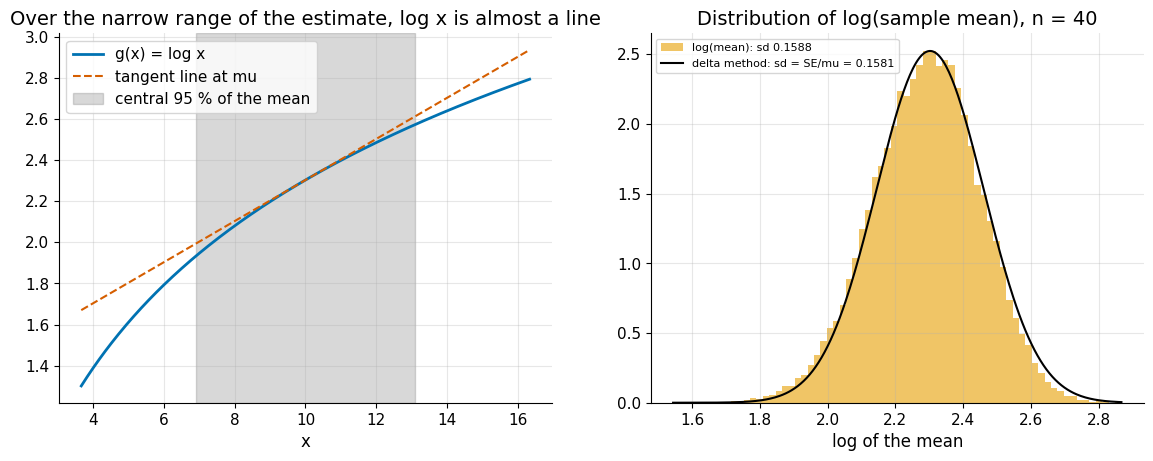

In [2]:
mu, sigma, n = 10.0, 10.0, 40
xbar = rng.exponential(mu, (50_000, n)).mean(axis=1)
se_x = sigma / np.sqrt(n)
xs = np.linspace(mu - 4 * se_x, mu + 4 * se_x, 300)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1]})
axes[0].plot(xs, np.log(xs), color=MAIN, linewidth=2, label="g(x) = log x")
axes[0].plot(xs, np.log(mu) + (xs - mu) / mu, color=HIGHLIGHT, linestyle="--", label="tangent line at mu")
axes[0].axvspan(mu - 1.96 * se_x, mu + 1.96 * se_x, color=NEUTRAL, alpha=0.25, label="central 95 % of the mean")
axes[0].set_title("Over the narrow range of the estimate, log x is almost a line"); axes[0].set_xlabel("x"); axes[0].legend()
lg = np.log(xbar)
axes[1].hist(lg, bins=70, density=True, color=SIM, alpha=0.6, label=f"log(mean): sd {lg.std():.4f}")
gx = np.linspace(lg.min(), lg.max(), 300)
axes[1].plot(gx, stats.norm.pdf(gx, np.log(mu), se_x / mu), color="black", label=f"delta method: sd = SE/mu = {se_x / mu:.4f}")
axes[1].set_title("Distribution of log(sample mean), n = 40"); axes[1].set_xlabel("log of the mean"); axes[1].legend(fontsize=8)
plt.show()

### 7.2 Four functions, one estimate
For Exponential data ($\mu=10$, $n=30$) the sample mean is pushed through $\log$, $\sqrt{\ }$, $1/x$ and $\exp(x/10)$. The delta-method Normal (black) against the simulated distribution (green): excellent for the first two, a visible skew for $1/x$ and especially $\exp$ (strong curvature).

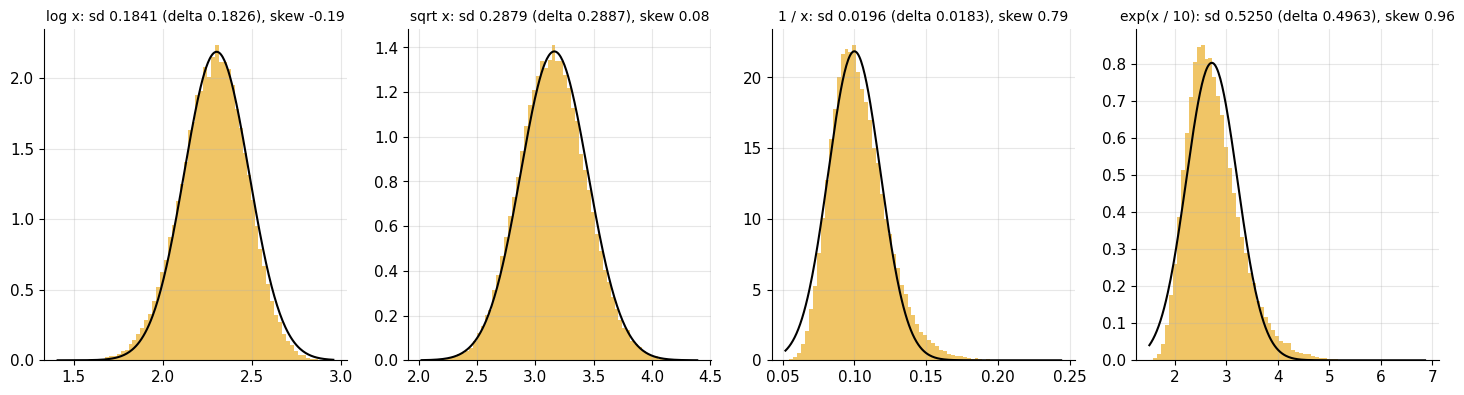

In [3]:
n = 30
xbar = rng.exponential(mu, (80_000, n)).mean(axis=1)
se_x = sigma / np.sqrt(n)
funcs = {"log x": (np.log, lambda m: 1 / m), "sqrt x": (np.sqrt, lambda m: 0.5 / np.sqrt(m)),
         "1 / x": (lambda x: 1 / x, lambda m: -1 / m**2), "exp(x / 10)": (lambda x: np.exp(x / 10), lambda m: np.exp(m / 10) / 10)}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
delta_check = {}
for ax, (name, (g, dg)) in zip(axes, funcs.items()):
    vals = g(xbar); sd_delta = abs(dg(mu)) * se_x
    ax.hist(vals, bins=70, density=True, color=SIM, alpha=0.6)
    gx = np.linspace(vals.min(), vals.max(), 300)
    ax.plot(gx, stats.norm.pdf(gx, g(mu), sd_delta), color="black")
    ax.set_title(f"{name}: sd {vals.std():.4f} (delta {sd_delta:.4f}), skew {stats.skew(vals):.2f}", fontsize=10)
    delta_check[name] = (vals.std(), sd_delta)
plt.show()

### 7.3 How good is it? Accuracy against the sample size
Kolmogorov distance between the simulated distribution of $g(\bar X)$ and its delta-method Normal, for $g=1/x$ and $g=\log x$. The error shrinks like $1/\sqrt n$, as for the CLT itself, but the nonlinear $1/x$ is always worse than the log.

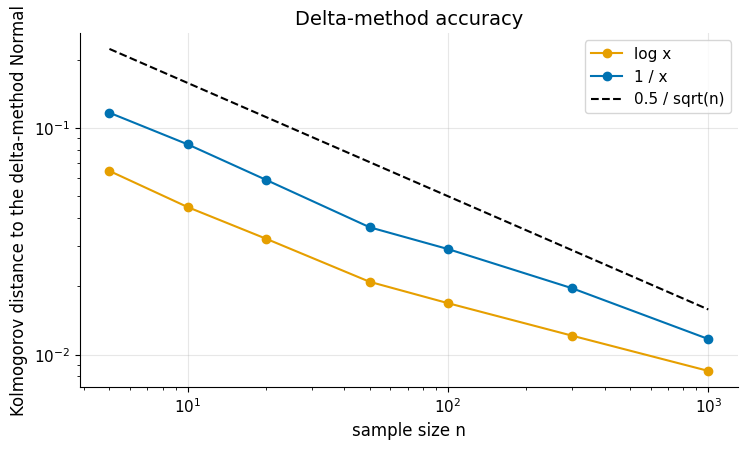

In [4]:
ns = [5, 10, 20, 50, 100, 300, 1000]
dist = {"log x": [], "1 / x": []}
for nn in ns:
    xb = rng.exponential(mu, (40_000, nn)).mean(axis=1)
    for name, g, dg in [("log x", np.log, lambda m: 1 / m), ("1 / x", lambda x: 1 / x, lambda m: -1 / m**2)]:
        v = np.sort(g(xb)); cdf_sim = np.arange(1, len(v) + 1) / len(v)
        dist[name].append(np.max(np.abs(cdf_sim - stats.norm.cdf(v, g(mu), abs(dg(mu)) * sigma / np.sqrt(nn)))))
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for (name, d), c in zip(dist.items(), [SIM, MAIN]):
    ax.loglog(ns, d, "o-", color=c, label=name)
ax.loglog(ns, 0.5 / np.sqrt(ns), "k--", label="0.5 / sqrt(n)")
ax.set_xlabel("sample size n"); ax.set_ylabel("Kolmogorov distance to the delta-method Normal"); ax.set_title("Delta-method accuracy"); ax.legend()
plt.show()
assert dist["log x"][-1] < dist["log x"][0] and dist["1 / x"][-1] < dist["1 / x"][0]

### 7.4 Variance-stabilising transformations
The SD of a sample proportion depends on $p$ (left, orange); after $2\arcsin\sqrt{\hat p}$ it is flat at $1/\sqrt n$ (left, green). Same for Poisson counts: the SD of $X$ is $\sqrt\lambda$, the SD of $\sqrt X$ is about $1/2$ whatever $\lambda$ is.

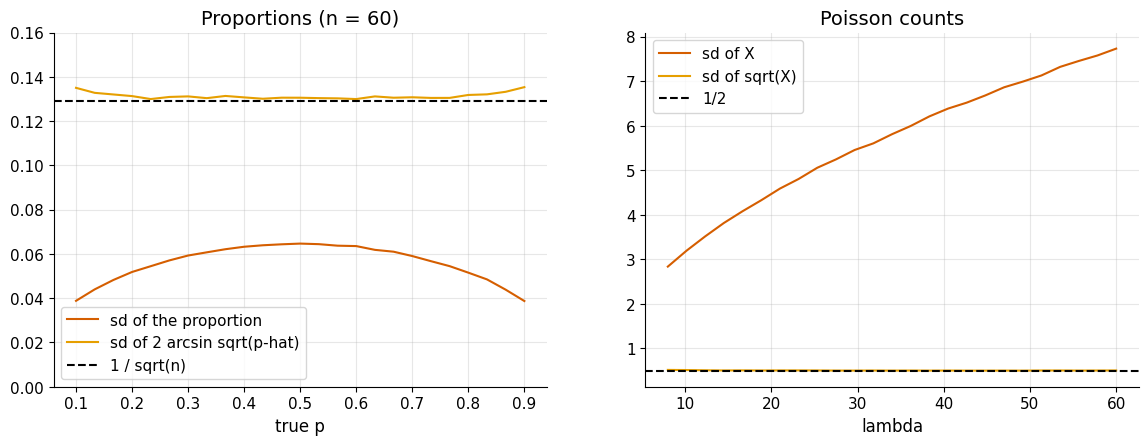

In [5]:
n = 60
ps = np.linspace(0.1, 0.9, 25)
sd_raw = [np.std(rng.binomial(n, p, 40_000) / n) for p in ps]
sd_arc = [np.std(2 * np.arcsin(np.sqrt(rng.binomial(n, p, 40_000) / n))) for p in ps]
lams = np.linspace(8, 60, 25)
sd_pois = [np.std(rng.poisson(l, 40_000)) for l in lams]
sd_sqrt = [np.std(np.sqrt(rng.poisson(l, 40_000))) for l in lams]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(ps, sd_raw, color=HIGHLIGHT, label="sd of the proportion"); axes[0].plot(ps, sd_arc, color=SIM, label="sd of 2 arcsin sqrt(p-hat)")
axes[0].axhline(1 / np.sqrt(n), color="black", linestyle="--", label="1 / sqrt(n)"); axes[0].set_xlabel("true p"); axes[0].set_ylim(0, 0.16); axes[0].legend(); axes[0].set_title("Proportions (n = 60)")
axes[1].plot(lams, sd_pois, color=HIGHLIGHT, label="sd of X"); axes[1].plot(lams, sd_sqrt, color=SIM, label="sd of sqrt(X)")
axes[1].axhline(0.5, color="black", linestyle="--", label="1/2"); axes[1].set_xlabel("lambda"); axes[1].legend(); axes[1].set_title("Poisson counts")
plt.show()
assert np.ptp(sd_arc) < 0.025 and np.ptp(sd_sqrt) < 0.06 and np.ptp(sd_raw) > 2 * np.ptp(sd_arc)

### 7.5 Slutsky in action: replacing sigma by s
The z-statistic with the *true* $\sigma$ is exactly Normal in the limit; with the *estimated* $s$ it has heavier tails for small $n$ (it is a $t$ for Normal data) and converges to the same Normal as $n$ grows. Exponential data: share of $|z|>1.96$.

In [6]:
rows = []
for nn in [5, 10, 30, 100, 1000]:
    data = rng.exponential(mu, (60_000, nn))
    zt = (data.mean(axis=1) - mu) / (sigma / np.sqrt(nn))
    zs = (data.mean(axis=1) - mu) / (data.std(axis=1, ddof=1) / np.sqrt(nn))
    rows.append({"n": nn, "P(|z| > 1.96), true sigma": np.mean(np.abs(zt) > 1.96), "P(|z| > 1.96), estimated s": np.mean(np.abs(zs) > 1.96)})
sl = pd.DataFrame(rows)
print(sl.round(4).to_string(index=False))
assert abs(sl["P(|z| > 1.96), estimated s"].iloc[-1] - 0.05) < 0.012

   n  P(|z| > 1.96), true sigma  P(|z| > 1.96), estimated s
   5                     0.0436                      0.1871
  10                     0.0453                      0.1313
  30                     0.0460                      0.0821
 100                     0.0495                      0.0609
1000                     0.0509                      0.0515


## 8. 3D visuals

### 8.1 Static: the ratio $x/y$ and its tangent plane
The ratio $R(x,y)=y/x$ near $(\mu_x,\mu_y)=(5,25)$ with 400 sample points $(\bar x,\bar y)$ drawn from the sampling distribution of the pair of means. The points lie in a small blob where the surface is almost the tangent plane (the multivariate delta method).

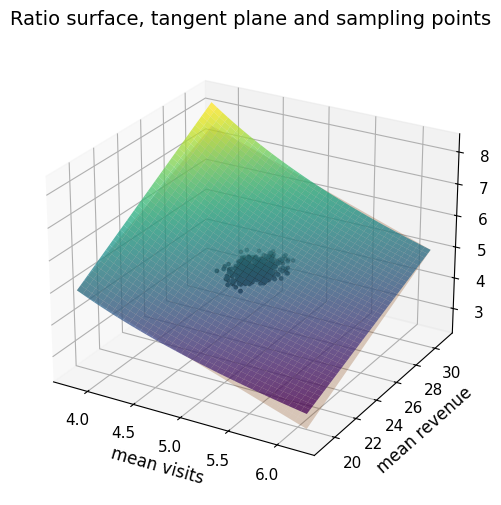

In [7]:
mx, my = 5.0, 25.0
xs_, ys_ = np.linspace(mx - 1.2, mx + 1.2, 40), np.linspace(my - 6, my + 6, 40)
X, Y = np.meshgrid(xs_, ys_)
R0 = my / mx
plane = R0 + (-my / mx**2) * (X - mx) + (1 / mx) * (Y - my)
cov_pair = np.array([[4, 12], [12, 136]]) / 400
pts = rng.multivariate_normal([mx, my], cov_pair, 400)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Y / X, cmap="viridis", alpha=0.75, edgecolor="none")
ax.plot_surface(X, Y, plane, color=HIGHLIGHT, alpha=0.25, edgecolor="none")
ax.scatter(pts[:, 0], pts[:, 1], pts[:, 1] / pts[:, 0], color="black", s=6)
ax.set_title("Ratio surface, tangent plane and sampling points"); ax.set_xlabel("mean visits"); ax.set_ylabel("mean revenue"); ax.set_zlabel("revenue per visit")
ax.view_init(elev=25, azim=-60)
plt.show()

### 8.2 Static: the SE of the ratio over (correlation, relative spread of the denominator)
$\mathrm{SE}(\hat R)=\frac1{\sqrt n\mu_x}\sqrt{\sigma_y^2+R^2\sigma_x^2-2R\rho\sigma_x\sigma_y}$. With $\rho$ near 1 the numerator and denominator move together and the ratio is steady; with $\rho=0$ the noise adds.

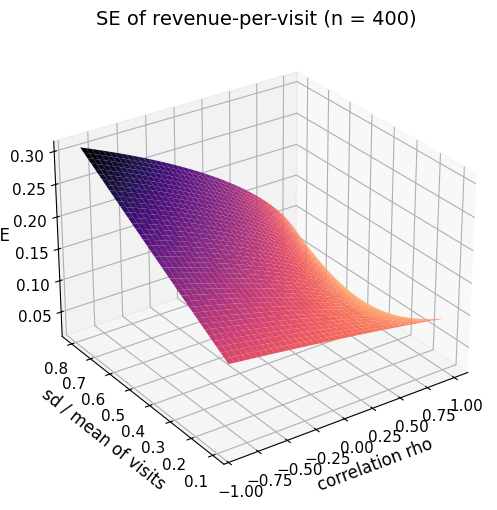

In [8]:
rho_ax = np.linspace(-0.9, 0.99, 40)
cvx_ax = np.linspace(0.1, 0.8, 40)                     # sigma_x / mu_x
sy_, Rr = 11.66, 5.0
def se_ratio(rho, cvx, n=400):
    sx = cvx * mx
    return np.sqrt(sy_**2 + Rr**2 * sx**2 - 2 * Rr * rho * sx * sy_) / (np.sqrt(n) * mx)
Rg, Cg = np.meshgrid(rho_ax, cvx_ax)
SEg = se_ratio(Rg, Cg)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Rg, Cg, SEg, cmap="magma_r", edgecolor="none")
ax.set_title("SE of revenue-per-visit (n = 400)"); ax.set_xlabel("correlation rho"); ax.set_ylabel("sd / mean of visits"); ax.set_zlabel("SE")
ax.view_init(elev=28, azim=-125)
plt.show()

### 8.3 Interactive Plotly version of 8.2
Hover to read the SE for any correlation and relative spread.

In [9]:
fig = go.Figure(go.Surface(x=rho_ax, y=cvx_ax, z=SEg, colorscale="Magma", reversescale=True))
fig.update_layout(title="SE of the ratio estimator", width=750, height=550, scene=dict(xaxis_title="correlation", yaxis_title="sd/mean of visits", zaxis_title="SE"))
fig.show()

## 9. Simulation vs theory

### 9.1 The delta-method SE against the simulated SE
For six functions of the mean of $n=100$ Exponential(10) draws, the simulated standard deviation of $g(\bar X)$ against $|g'(\mu)|\sigma/\sqrt n$ (the ratio column is within 2.4 % of 1 for every function, the curved ones, $1/x$ and $\exp$, being the roughest).

In [10]:
n = 100
xb = rng.exponential(mu, (200_000, n)).mean(axis=1)
specs = {"x": (lambda x: x, lambda m: 1.0), "log x": (np.log, lambda m: 1 / m), "sqrt x": (np.sqrt, lambda m: 0.5 / np.sqrt(m)),
         "1 / x": (lambda x: 1 / x, lambda m: -1 / m**2), "x^2": (lambda x: x**2, lambda m: 2 * m), "exp(x / 10)": (lambda x: np.exp(x / 10), lambda m: np.exp(m / 10) / 10)}
rows = []
for name, (g, dg) in specs.items():
    rows.append({"g": name, "simulated SD": g(xb).std(), "delta method": abs(dg(mu)) * sigma / np.sqrt(n)})
tab = pd.DataFrame(rows); tab["ratio"] = tab["simulated SD"] / tab["delta method"]
print(tab.round(5).to_string(index=False))
assert tab["ratio"].between(0.97, 1.06).all()

          g  simulated SD  delta method   ratio
          x       1.00291       1.00000 1.00291
      log x       0.10054       0.10000 1.00540
     sqrt x       0.15847       0.15811 1.00226
      1 / x       0.01023       0.01000 1.02335
        x^2      20.31097      20.00000 1.01555
exp(x / 10)       0.27751       0.27183 1.02091


### 9.2 Second-order delta: $g(x)=x^2$ at $\mu=0$
For Normal data with $\mu=0$, $\sigma=1$: $n\bar X^2\sim\chi^2_1$ exactly. The first-order delta method predicts zero spread: wrong. The second-order version is right.

n * mean^2: mean 0.995 (chi-square(1): 1), variance 1.966 (chi-square(1): 2), skewness 2.80 (chi-square(1): 2.83)


KS test against chi-square(1): D = 0.0016


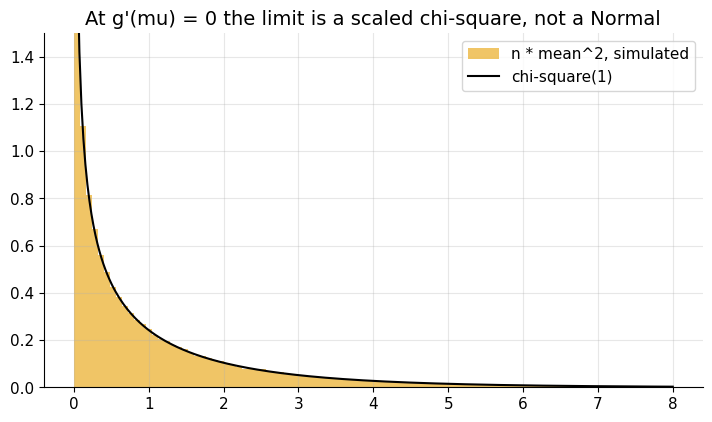

In [11]:
n0 = 50
xb0 = rng.normal(0, 1, (200_000, n0)).mean(axis=1)
v = n0 * xb0**2
print(f"n * mean^2: mean {v.mean():.3f} (chi-square(1): 1), variance {v.var():.3f} (chi-square(1): 2), skewness {stats.skew(v):.2f} (chi-square(1): {np.sqrt(8):.2f})")
ks = stats.kstest(v, stats.chi2(1).cdf)
print(f"KS test against chi-square(1): D = {ks.statistic:.4f}")
assert ks.statistic < 0.01
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.hist(v, bins=100, range=(0, 8), density=True, color=SIM, alpha=0.6, label="n * mean^2, simulated")
gx = np.linspace(0.02, 8, 300); ax.plot(gx, stats.chi2(1).pdf(gx), color="black", label="chi-square(1)")
ax.set_ylim(0, 1.5); ax.set_title("At g'(mu) = 0 the limit is a scaled chi-square, not a Normal"); ax.legend()
plt.show()

## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [12]:
from scipy.optimize import approx_fprime
g_ratio = lambda t: t[1] / t[0]
grad = approx_fprime(np.array([5.0, 25.0]), g_ratio, 1e-6)
print("numerical gradient of y/x at (5, 25):", grad.round(4), "(exact: -y/x^2 = -1, 1/x = 0.2)")
cov = np.array([[4.0, 12.0], [12.0, 136.0]])
print("delta variance of the ratio per observation: grad' Sigma grad =", round(float(grad @ cov @ grad), 4), "-> SE with n = 400:", round(float(np.sqrt(grad @ cov @ grad / 400)), 4))
print("Woolf SE of a log odds ratio from a 2x2 table [[a, b], [c, d]]: sqrt(1/a + 1/b + 1/c + 1/d) =", round(np.sqrt(1 / 156 + 1 / 2244 + 1 / 120 + 1 / 2280), 5))
print("scipy odds ratio and CI: stats.contingency.odds_ratio(table).confidence_interval() ->")
res = stats.contingency.odds_ratio([[156, 2244], [120, 2280]])
print("  OR", round(res.statistic, 4), "(conditional MLE, not the sample OR; sample OR =", round((156 * 2280) / (2244 * 120), 4), ")")
print("z critical value:", round(stats.norm.isf(0.025), 4), "| p-value for z = 2.2256:", round(2 * stats.norm.sf(2.2256), 4))
print("chi-square(1) quantile for the second-order case:", round(stats.chi2(1).ppf(0.95), 3))

numerical gradient of y/x at (5, 25): [-1.   0.2] (exact: -y/x^2 = -1, 1/x = 0.2)
delta variance of the ratio per observation: grad' Sigma grad = 4.64 -> SE with n = 400: 0.1077
Woolf SE of a log odds ratio from a 2x2 table [[a, b], [c, d]]: sqrt(1/a + 1/b + 1/c + 1/d) = 0.12501
scipy odds ratio and CI: stats.contingency.odds_ratio(table).confidence_interval() ->
  OR 1.3208 (conditional MLE, not the sample OR; sample OR = 1.3209 )
z critical value: 1.96 | p-value for z = 2.2256: 0.026
chi-square(1) quantile for the second-order case: 3.841


## 11. Real-world worked examples

---
### Example 1 (main): is the new checkout really better? A confidence interval for an odds ratio

**Scenario.** An A/B test on a checkout page: **control A** converted **120 of 2,400** visitors (5.0 %), **variant B** converted **156 of 2,400** (6.5 %). The product team asks about **odds ratios** (the standard effect measure in logistic regression) and **relative risk**.

**Questions**
1. Give the **odds ratio** and a **95 % confidence interval** (delta method on the log).
2. Give the **relative risk** $\hat p_B/\hat p_A$ and a 95 % interval.
3. Is the effect significant? Give the **z statistic and p-value** for $H_0$: odds ratio $=1$.
4. Check by simulation that the interval **covers** the truth about 95 % of the time.

### 11.1 By hand
**Q1.** Odds of B: $156/2244=0.06952$; odds of A: $120/2280=0.05263$; $\widehat{OR}=1.3208$, $\ln\widehat{OR}=0.2782$. Woolf SE: $\sqrt{\tfrac1{156}+\tfrac1{2244}+\tfrac1{120}+\tfrac1{2280}}=\sqrt{0.006410+0.000446+0.008333+0.000439}=\sqrt{0.015628}=0.1250$. Interval for $\ln OR$: $0.2782\pm1.96\times0.1250=(0.0332,\,0.5232)$; exponentiate: **OR in (1.034, 1.688)**.

**Q2.** $\widehat{RR}=0.065/0.05=1.30$. For $\ln\hat p$ the delta method gives $\mathrm{SE}(\ln\hat p)=\sqrt{(1-p)/(np)}$, so $\mathrm{SE}(\ln RR)=\sqrt{\tfrac{1-p_B}{n p_B}+\tfrac{1-p_A}{n p_A}}=\sqrt{\tfrac{0.935}{156}+\tfrac{0.95}{120}}=\sqrt{0.005994+0.007917}=0.1179$. Interval $\ln1.30\pm1.96\times0.1179=(0.0312,\,0.4934)$, i.e. **RR in (1.032, 1.638)**.

**Q3.** $z=0.2782/0.1250=2.226$, two-sided $p=0.0260$.

In [13]:
a, n_a, b, n_b = 120, 2400, 156, 2400          # A and B: conversions, visitors
or_hat = (b / (n_b - b)) / (a / (n_a - a))
se_log_or = np.sqrt(1 / b + 1 / (n_b - b) + 1 / a + 1 / (n_a - a))
z95 = stats.norm.isf(0.025)
ci_or = np.exp(np.log(or_hat) + np.array([-1, 1]) * z95 * se_log_or)
print(f"Q1: OR = {or_hat:.4f}, SE(log OR) = {se_log_or:.4f}, 95% CI ({ci_or[0]:.3f}, {ci_or[1]:.3f})")
rr_hat = (b / n_b) / (a / n_a)
se_log_rr = np.sqrt((1 - b / n_b) / b + (1 - a / n_a) / a)
ci_rr = np.exp(np.log(rr_hat) + np.array([-1, 1]) * z95 * se_log_rr)
print(f"Q2: RR = {rr_hat:.4f}, SE(log RR) = {se_log_rr:.4f}, 95% CI ({ci_rr[0]:.3f}, {ci_rr[1]:.3f})")
z_stat = np.log(or_hat) / se_log_or
print(f"Q3: z = {z_stat:.3f}, two-sided p = {2 * stats.norm.sf(z_stat):.4f}")

Q1: OR = 1.3209, SE(log OR) = 0.1250, 95% CI (1.034, 1.688)
Q2: RR = 1.3000, SE(log RR) = 0.1179, 95% CI (1.032, 1.638)
Q3: z = 2.226, two-sided p = 0.0260


### 11.2 In code with `scipy`, and the asserts

In [14]:
assert abs(or_hat - 1.3208) < 1e-3 and abs(se_log_or - 0.1250) < 5e-4
assert abs(ci_or[0] - 1.034) < 2e-3 and abs(ci_or[1] - 1.688) < 3e-3
assert abs(rr_hat - 1.30) < 1e-9 and abs(se_log_rr - 0.1179) < 5e-4 and abs(ci_rr[0] - 1.032) < 2e-3
assert abs(z_stat - 2.226) < 2e-3 and abs(2 * stats.norm.sf(z_stat) - 0.0260) < 5e-4
# the delta method on the logit scale gives the same standard error for each proportion
pa, pb = a / n_a, b / n_b
assert abs(np.sqrt(1 / (n_a * pa * (1 - pa)) + 1 / (n_b * pb * (1 - pb))) - se_log_or) < 2e-3
# agreement with scipy's Wald-type result from statsmodels-free route: Fisher exact p-value is close to the Wald p-value
fisher_p = stats.fisher_exact([[b, n_b - b], [a, n_a - a]])[1]
print(f"Fisher exact p = {fisher_p:.4f} (Wald p = {2 * stats.norm.sf(z_stat):.4f})")
assert abs(fisher_p - 2 * stats.norm.sf(z_stat)) < 0.01
print("all checks passed")

Fisher exact p = 0.0298 (Wald p = 0.0260)
all checks passed


### 11.3 Verify by simulation
Take the observed rates as the truth, simulate 100,000 A/B tests, build the delta-method interval each time and count how often it contains the true odds ratio; also compare the simulated SD of $\ln\widehat{OR}$ with the formula.

In [15]:
sim_rng = np.random.default_rng(31)
true_or = (pb / (1 - pb)) / (pa / (1 - pa)); reps = 100_000
sa, sb = sim_rng.binomial(n_a, pa, reps), sim_rng.binomial(n_b, pb, reps)
lor = np.log((sb / (n_b - sb)) / (sa / (n_a - sa)))
se = np.sqrt(1 / sb + 1 / (n_b - sb) + 1 / sa + 1 / (n_a - sa))
cover_or = np.mean(np.abs(lor - np.log(true_or)) <= z95 * se)
print(f"simulated SD of log OR {lor.std():.4f} vs delta formula {se_log_or:.4f}; coverage of the 95% interval {cover_or:.4f}")
reject_null = np.mean(np.abs(lor / se) > z95)
print(f"power of this test to detect the observed effect: {reject_null:.3f}")
assert abs(lor.std() - se_log_or) < 0.004 and 0.94 < cover_or < 0.965

simulated SD of log OR 0.1253 vs delta formula 0.1250; coverage of the 95% interval 0.9512
power of this test to detect the observed effect: 0.611


### 11.4 Plots with the regions shaded

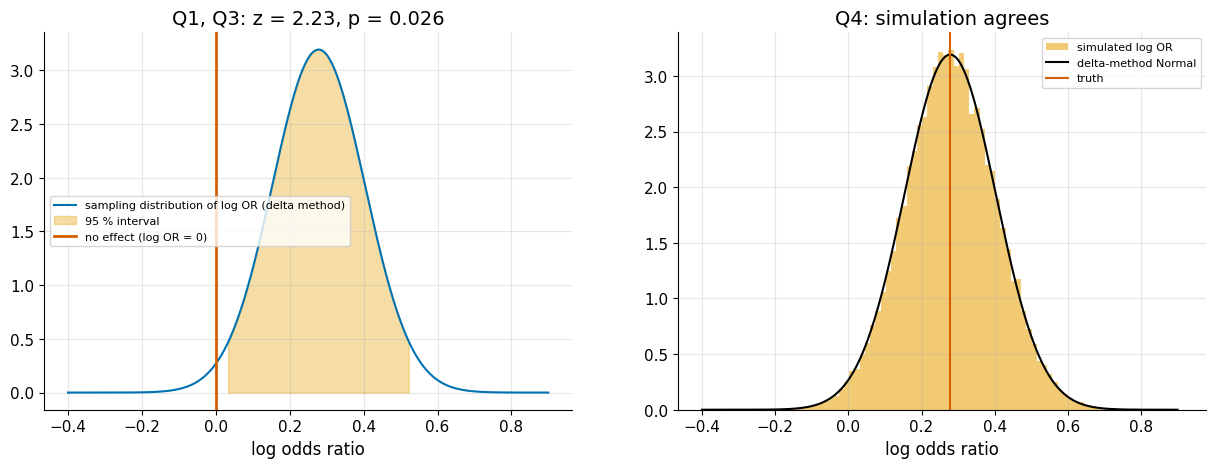

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
xs = np.linspace(-0.4, 0.9, 400)
axes[0].plot(xs, stats.norm.pdf(xs, np.log(or_hat), se_log_or), color=MAIN, label="sampling distribution of log OR (delta method)")
axes[0].fill_between(xs, 0, stats.norm.pdf(xs, np.log(or_hat), se_log_or), where=(xs >= np.log(ci_or[0])) & (xs <= np.log(ci_or[1])), color=SIM, alpha=0.35, label="95 % interval")
axes[0].axvline(0, color=HIGHLIGHT, linewidth=2, label="no effect (log OR = 0)")
axes[0].set_title(f"Q1, Q3: z = {z_stat:.2f}, p = {2 * stats.norm.sf(z_stat):.3f}"); axes[0].set_xlabel("log odds ratio"); axes[0].legend(fontsize=8)
axes[1].hist(lor, bins=80, density=True, color=SIM, alpha=0.55, label="simulated log OR")
axes[1].plot(xs, stats.norm.pdf(xs, np.log(true_or), se_log_or), color="black", label="delta-method Normal")
axes[1].axvline(np.log(true_or), color=HIGHLIGHT, label="truth"); axes[1].set_title("Q4: simulation agrees"); axes[1].set_xlabel("log odds ratio"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **Effect size.** The odds of converting are **32 % higher** with the new checkout (OR 1.32), and the interval is (1.03, 1.69): even the pessimistic end is a real improvement, the optimistic end is a 69 % increase. The relative risk (1.30, interval 1.03 to 1.64) says the same in more intuitive terms: about **30 % more conversions**.
- **Significance.** $z=2.23$, $p=0.026$: unlikely to be chance at the usual 5 % level. The exact Fisher test gives 0.030, so the conclusion does not depend on the approximation.
- **Reliability of the method.** The simulated SD of $\ln OR$ (0.1253) matches the delta formula (0.1250) and the interval covers the truth 95.1 % of the time.
- **Power caveat.** A test with this size would detect an effect this large only about **61 %** of the time: a "significant" result of this size is plausible but the *estimate* is imprecise (the interval is wide). Collect more data before building a revenue forecast on the 30 %.
- **Decision.** Roll out the variant, but plan on a lift somewhere between 3 % and 64 % rather than a firm 30 %.

---
### Example 2: revenue per visit, a ratio of two correlated averages

**Scenario.** A shop tracks **$n=400$** customers. Visits per customer have mean 5 and SD 2; revenue per customer has mean 25 and SD 11.66; their covariance is 12 (correlation 0.51). The business KPI is **revenue per visit** $R=\bar Y/\bar X=5$. What is its standard error, and what would we get if we **wrongly ignored the correlation**?

### 11.6 By hand, in code and by simulation
**By hand (multivariate delta).** $\mathrm{Var}(\hat R)\approx\dfrac{\sigma_y^2+R^2\sigma_x^2-2R\,\mathrm{Cov}}{n\mu_x^2}=\dfrac{136+25\cdot4-2\cdot5\cdot12}{400\cdot25}=\dfrac{116}{10000}$, so $\mathrm{SE}=0.1077$ and the 95 % interval is $5\pm0.211$. Ignoring the covariance gives $\sqrt{236/10000}=0.1536$, about 43 % too large (it forgets the term $-2R\,\mathrm{Cov}=-120$).

delta-method SE 0.1077 | SE ignoring the covariance 0.1536


simulated: mean 5.0019, SD 0.1075; share within the delta 95% band: 0.9519


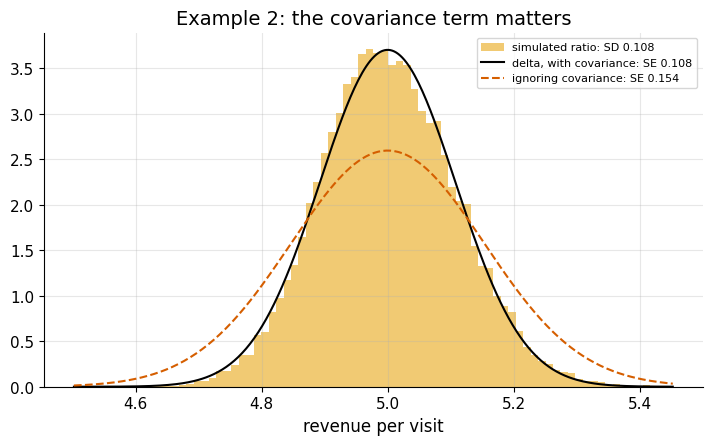

In [17]:
n_cust, R_true = 400, 5.0
se_delta = np.sqrt((136 + R_true**2 * 4 - 2 * R_true * 12) / (n_cust * 25))
se_wrong = np.sqrt((136 + R_true**2 * 4) / (n_cust * 25))
print(f"delta-method SE {se_delta:.4f} | SE ignoring the covariance {se_wrong:.4f}")
# population: visits = 1 + Poisson(4) (mean 5, sd 2); revenue = 3 * visits + 10 * Exponential(1) (mean 25, var 9*4 + 100 = 136, cov = 12)
est = np.empty(20_000)
cover_rng = np.random.default_rng(41)
for i in range(est.size):
    x = 1 + cover_rng.poisson(4, n_cust); y = 3 * x + 10 * cover_rng.exponential(1, n_cust)
    est[i] = y.mean() / x.mean()
print(f"simulated: mean {est.mean():.4f}, SD {est.std():.4f}; share within the delta 95% band: {np.mean(np.abs(est - R_true) <= 1.96 * se_delta):.4f}")
assert abs(est.std() - se_delta) < 0.004 and abs(est.std() - se_wrong) > 0.03
assert abs(np.sqrt(np.array([-1, 0.2]) @ np.array([[4, 12], [12, 136]]) @ np.array([-1, 0.2]) / n_cust) - se_delta) < 1e-9
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.hist(est, bins=80, density=True, color=SIM, alpha=0.55, label=f"simulated ratio: SD {est.std():.3f}")
gx = np.linspace(est.min(), est.max(), 300)
ax.plot(gx, stats.norm.pdf(gx, R_true, se_delta), color="black", label=f"delta, with covariance: SE {se_delta:.3f}")
ax.plot(gx, stats.norm.pdf(gx, R_true, se_wrong), color=HIGHLIGHT, linestyle="--", label=f"ignoring covariance: SE {se_wrong:.3f}")
ax.set_xlabel("revenue per visit"); ax.set_title("Example 2: the covariance term matters"); ax.legend(fontsize=8)
plt.show()

### 11.6b Interpretation and decision (Example 2)
- The revenue per visit is **5.00 with SE 0.108**, so the 95 % interval is about (4.79, 5.21). The simulation gives SD 0.1075, the delta formula 0.1077, and 95.2 % of simulated estimates fall inside the delta band.
- **The covariance term matters.** Ignoring it gives SE 0.154, **43 % too large**. Customers who visit more also spend more, so the numerator and denominator move together and the ratio is steadier than either part. At correlation 0.9 the SE would fall to 0.051; at 0 it would be 0.154 (Exercise 4).
- **Decision.** Report the KPI with the correct interval (±0.21), not the inflated one (±0.30); an A/B test on this metric needs far fewer customers than the naive calculation says.

---
### Example 3: when the first-order delta method fails (estimating $\mu^2$)

**Scenario.** A signal-processing team estimates the **power** $\theta=\mu^2$ of a small mean signal from $n=50$ measurements with noise SD $\sigma=1$, using $\bar X^2$. The first-order delta method says $\mathrm{SE}\approx2|\mu|\sigma/\sqrt n$. When is that trustworthy?

### 11.7 By hand, in code and by simulation
**By hand.** Exactly, for Normal data $\mathrm{Var}(\bar X^2)=\dfrac{4\mu^2\sigma^2}{n}+\dfrac{2\sigma^4}{n^2}$: the first term is the delta-method variance, the second is the curvature (second-order) term. For $\mu=0.1$: $0.0008+0.0008=0.0016$, SD $=0.040$, against the delta-method $0.0283$. The first-order result is good only when $4\mu^2\sigma^2/n\gg2\sigma^4/n^2$, i.e. when $|\mu|\gg\sigma/\sqrt{2n}=0.1$.

 mu  simulated SD of xbar^2  first-order delta  exact formula
0.0                  0.0283             0.0000         0.0283
0.1                  0.0403             0.0283         0.0400
0.3                  0.0892             0.0849         0.0894
1.0                  0.2846             0.2828         0.2843


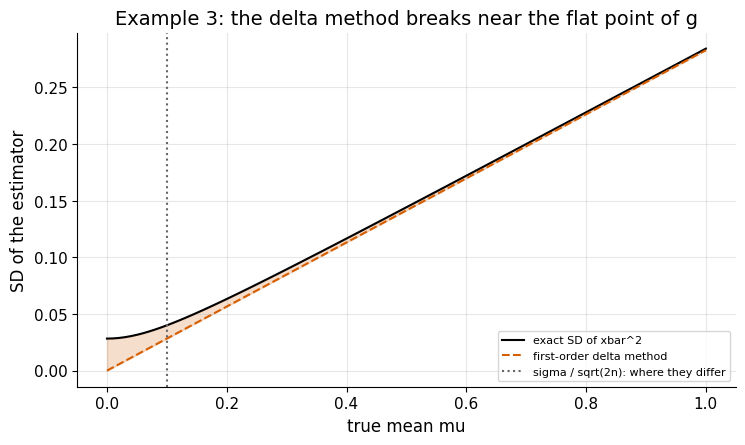

In [18]:
n0, sig0 = 50, 1.0
rows = []
for m in [0.0, 0.1, 0.3, 1.0]:
    sq = (rng.normal(m, sig0 / np.sqrt(n0), 400_000)) ** 2
    first = 2 * abs(m) * sig0 / np.sqrt(n0)
    exact = np.sqrt(4 * m**2 * sig0**2 / n0 + 2 * sig0**4 / n0**2)
    rows.append({"mu": m, "simulated SD of xbar^2": sq.std(), "first-order delta": first, "exact formula": exact})
ex3 = pd.DataFrame(rows)
print(ex3.round(4).to_string(index=False))
assert np.allclose(ex3["simulated SD of xbar^2"], ex3["exact formula"], rtol=0.02, atol=1e-4)
assert abs(ex3.loc[ex3.mu == 0.1, "simulated SD of xbar^2"].iloc[0] - 0.040) < 0.002 and ex3.loc[ex3.mu == 0.0, "first-order delta"].iloc[0] == 0
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ms = np.linspace(0, 1, 100)
ax.plot(ms, np.sqrt(4 * ms**2 / n0 + 2 / n0**2), color="black", label="exact SD of xbar^2")
ax.plot(ms, 2 * ms / np.sqrt(n0), color=HIGHLIGHT, linestyle="--", label="first-order delta method")
ax.axvline(1 / np.sqrt(2 * n0), color=NEUTRAL, linestyle=":", label="sigma / sqrt(2n): where they differ")
ax.fill_between(ms, 2 * ms / np.sqrt(n0), np.sqrt(4 * ms**2 / n0 + 2 / n0**2), color=HIGHLIGHT, alpha=0.2)
ax.set_xlabel("true mean mu"); ax.set_ylabel("SD of the estimator"); ax.set_title("Example 3: the delta method breaks near the flat point of g"); ax.legend(fontsize=8)
plt.show()

### 11.7b Interpretation and decision (Example 3)
- For a true mean of 0.3 or 1.0 the first-order delta SE (0.085, 0.283) is within 5 % of the truth (0.089, 0.284). At $\mu=0.1$ it is **30 % too small** (0.028 against 0.040), and at $\mu=0$ it says zero while the true SD is 0.028.
- The rule from the exact formula: the first-order result is trustworthy when $|\mu|\gg\sigma/\sqrt{2n}=0.1$. Near zero the estimator $\bar X^2$ behaves like $\sigma^2\chi^2_1/n$ (Section 9.2), which is skewed and not Normal.
- **Decision.** For a weak signal (mean comparable to the noise level divided by $\sqrt n$), do not report $\hat\theta\pm1.96\,\mathrm{SE}_{\text{delta}}$; use the second-order (chi-square) result, the exact formula or the bootstrap.

## 12. Where it is used

### Statistics
- **Standard errors and Wald intervals** for any smooth function of estimates: odds ratios, relative risks, rates, correlations (Fisher's $z$), coefficients of variation, elasticities.
- **Asymptotic distributions of estimators** (MLE of a transformed parameter, Module 06), and **variance-stabilising transformations** before ANOVA or regression.

### Data science
- **A/B tests** on ratios (revenue per visit, click-through per session): the ratio's SE needs the delta method with the covariance (Example 2); **log-transformed metrics** and relative lifts.
- **Forecast and KPI uncertainty** for derived metrics (margin = profit / revenue, churn-adjusted growth).

### ML and AI
- **Uncertainty propagation:** how noise in model outputs (probabilities, logits) propagates through a transform (softmax, calibration, log-odds); the **Laplace approximation** and the **Fisher information** use the same linearisation.
- **Error bars on ratio metrics** (precision, recall, F1) and on **sensitivity analysis** ($\nabla g^{\top}\Sigma\nabla g$ is the basis of gradient-based uncertainty propagation).

## 13. Common pitfalls and misconceptions

- **Delta method needs $g'(\theta)\ne0$.** At a stationary point the first-order SE is zero and wrong (Example 3).
- **Small $n$ and strong curvature:** the approximation is first-order; for $1/x$ near zero or $\exp$ with a large slope, transform first or use the bootstrap (05_04).
- **Do not forget the covariance** for ratios and differences of dependent averages (Example 2); independence is not assumed by the formula.
- **Interval on the right scale:** build the interval for $\log OR$ (or $\log RR$) and exponentiate; $\widehat{OR}\pm1.96\,\mathrm{SE}_{OR}$ can be asymmetric in truth and may even include negative values.
- **Slutsky needs a constant limit:** you may replace $s$ by $\sigma$ because $s\to\sigma$; you may not replace a quantity that keeps fluctuating.
- **Rare cells:** with a zero or tiny cell the Woolf SE explodes; add 0.5 to each cell (Haldane) or use an exact method.
- **Relative risk is not odds ratio:** they agree only when the outcome is rare (here 1.30 against 1.32).

## 14. Exercises

1. Use the delta method to find the SE of $\hat\lambda=1/\bar X$ for Exponential data with mean 200 hours and $n=50$, and a 95 % interval for the failure rate $\lambda$.
2. A Poisson count of 36 events was observed in one hour. Use $\sqrt{X}$ to build a 95 % interval for $\lambda$ and compare it with the exact (Garwood) interval from `scipy`.
3. Show that for a proportion the variance-stabilising transform is $2\arcsin\sqrt{\hat p}$ with variance $1/n$, and verify numerically for $p=0.1$ and $p=0.5$ with $n=100$.
4. Revenue per visit again: if the correlation between visits and revenue were 0 (same SDs), what would the SE be? And if it were 0.9?
5. Odds ratio of a **rare** outcome: with cell counts 2, 998, 10, 990 compute the Woolf interval and the interval after adding 0.5 to each cell. Which do you trust, and why?
6. (Harder) For $g(x)=x^2$ and $\mu=0.1$, $\sigma=1$, $n=50$, simulate the distribution of $\bar X^2$ and compare its 97.5th percentile with the first-order delta-method upper limit $\mu^2+1.96\cdot2\mu\sigma/\sqrt n$.

Solutions are at the end.

## 15. Summary table

| Task | Formula | Where it breaks |
|---|---|---|
| Replace $\sigma$ by $s$ | Slutsky | tiny $n$ (use $t$) |
| SE of $g(\hat\theta)$ | $\|g'(\theta)\|\,\mathrm{SE}(\hat\theta)$ | $g'(\theta)=0$, strong curvature |
| SE of ratio $\bar Y/\bar X$ | $\sqrt{\sigma_y^2+R^2\sigma_x^2-2R\,\mathrm{Cov}}\,/(\sqrt n\mu_x)$ | $\mu_x$ near 0 |
| Odds ratio | $\exp(\ln\widehat{OR}\pm z\sqrt{1/a+1/b+1/c+1/d})$ | empty cells |
| Stabilise variance | $2\arcsin\sqrt{\hat p}$, $\sqrt X$, $\log$ | extreme $p$ or tiny counts |
| Zero slope | $n(g(T)-g(\theta))\to\frac12\sigma^2g''\chi^2_1$ | needs $g''\ne0$ |

## Solutions

In [19]:
lam, n1 = 1 / 200, 50
se1 = lam / np.sqrt(n1)
print(f"1: lambda-hat = {lam:.4f} per hour, SE = {se1:.5f}, 95% CI ({lam - 1.96 * se1:.5f}, {lam + 1.96 * se1:.5f})")
x2 = 36
lo2, hi2 = (np.sqrt(x2) - 1.96 / 2) ** 2, (np.sqrt(x2) + 1.96 / 2) ** 2
print(f"2: sqrt-interval ({lo2:.2f}, {hi2:.2f}) | exact Garwood ({stats.chi2.ppf(0.025, 2 * x2) / 2:.2f}, {stats.chi2.ppf(0.975, 2 * (x2 + 1)) / 2:.2f})")
for p_ in (0.1, 0.5):
    print(f"3: p = {p_}: sd of p-hat {np.std(rng.binomial(100, p_, 200_000) / 100):.4f}, sd of 2 arcsin sqrt(p-hat) {np.std(2 * np.arcsin(np.sqrt(rng.binomial(100, p_, 200_000) / 100))):.4f}, 1/sqrt(n) = 0.1")
se_r = lambda rho: np.sqrt(136 + 25 * 4 - 2 * 5 * rho * 2 * 11.66) / (np.sqrt(400) * 5)
print(f"4: rho = 0: SE {se_r(0):.4f} | rho = 0.51: {se_r(0.5145):.4f} | rho = 0.9: {se_r(0.9):.4f}")
cells = np.array([2, 998, 10, 990], float)
for label, c in [("raw", cells), ("+0.5", cells + 0.5)]:
    orr = (c[0] / c[1]) / (c[2] / c[3]); s = np.sqrt((1 / c).sum())
    print(f"5: {label}: OR {orr:.3f}, 95% CI ({orr * np.exp(-1.96 * s):.3f}, {orr * np.exp(1.96 * s):.3f})")
sq = rng.normal(0.1, 1 / np.sqrt(50), 1_000_000) ** 2
print(f"6: simulated 97.5th percentile {np.percentile(sq, 97.5):.4f} vs first-order upper limit {0.01 + 1.96 * 2 * 0.1 / np.sqrt(50):.4f}")

1: lambda-hat = 0.0050 per hour, SE = 0.00071, 95% CI (0.00361, 0.00639)
2: sqrt-interval (25.20, 48.72) | exact Garwood (25.21, 49.84)
3: p = 0.1: sd of p-hat 0.0300, sd of 2 arcsin sqrt(p-hat) 0.1020, 1/sqrt(n) = 0.1
3: p = 0.5: sd of p-hat 0.0501, sd of 2 arcsin sqrt(p-hat) 0.1001, 1/sqrt(n) = 0.1
4: rho = 0: SE 0.1536 | rho = 0.51: 0.1077 | rho = 0.9: 0.0511
5: raw: OR 0.198, 95% CI (0.043, 0.908)
5: +0.5: OR 0.236, 95% CI (0.059, 0.941)


6: simulated 97.5th percentile 0.1430 vs first-order upper limit 0.0654


**1.** $\hat\lambda=0.005$ per hour, $\mathrm{SE}=\lambda/\sqrt n=0.00071$ (relative error $1/\sqrt n=14$ %), 95 % interval (0.0036, 0.0064), i.e. a mean time between failures between 156 and 277 hours.

**2.** $\sqrt X$ has variance about $1/4$: interval $\big((6-0.98)^2,(6+0.98)^2\big)=(25.2,\,48.7)$. The exact Garwood interval is (25.2, 49.8): the lower limits agree, the upper limit of the square-root interval is a little short because of the skew of the Poisson.

**3.** By the delta method $g'(p)=1/\sqrt{p(1-p)}$ gives $g(p)=2\arcsin\sqrt p$ and $\mathrm{Var}\approx\frac{p(1-p)}n\cdot\frac1{p(1-p)}=\frac1n$. Simulated SD of $2\arcsin\sqrt{\hat p}$: 0.102 at $p=0.1$ and 0.100 at $p=0.5$ (target 0.1), while the SD of $\hat p$ itself changes from 0.030 to 0.050.

**4.** $\rho=0$: SE 0.154; $\rho=0.51$: 0.108; $\rho=0.9$: 0.051. Higher correlation, steadier ratio.

**5.** Raw cells: OR 0.198, interval (0.043, 0.908); with 0.5 added to every cell: OR 0.236, interval (0.059, 0.941). With so few events (2 and 10) the Woolf SE is unstable and the raw interval is optimistic (too narrow); the continuity-corrected one is the more cautious choice, and an exact method (Fisher) would be better still.

**6.** The simulated 97.5th percentile of $\bar X^2$ is 0.143, more than **twice** the first-order upper limit 0.065: the delta method misses the right skew near the flat point of $g$, as Example 3 explained.